## 1. Set Up


In [1]:
import os
import sys

# Dynamically point GDAL and PROJ to your active conda environment's folders
env_prefix = sys.prefix
os.environ["GDAL_DATA"] = os.path.join(env_prefix, "Library", "share", "gdal")
os.environ["PROJ_LIB"] = os.path.join(env_prefix, "Library", "share", "proj")

# Optional: prevents OpenMP threading conflicts in conda
os.environ["KMP_DUPLICATE_LIB_OK"] = "True"

import geopandas as gpd
import pandas as pd
import seaborn as sns
import pyogrio
import matplotlib
import matplotlib.pyplot as plt
import numpy as np
from pathlib import Path
from IPython.display import display
import os


In [3]:
PROJECT_DIR = Path.cwd().parent
DATA_DIR = PROJECT_DIR/"data"/"raw"
FIG_DIR = PROJECT_DIR/"docs"/"figures"

FIG_DIR.mkdir(parents=True, exist_ok=True) #understand later

CEDEN_PATH = DATA_DIR/"CEDEN_export.tsv"
NWIS_PATH = DATA_DIR/"resultphyschem.csv"
CARI_PATH = DATA_DIR/"CARI_v3_3_0.gdb"
S2S_PATH = DATA_DIR/"S2S_stations_2026-09-18-1455.csv"


# Loading all Datasets

In [4]:
df_ceden = pd.read_csv(CEDEN_PATH, sep="\t")
df_nwis = pd.read_csv(NWIS_PATH)
df_s2s = pd.read_csv(S2S_PATH)

gdf_cari = gpd.read_file(
    CARI_PATH,
    layer = "CARI_Polygons"
)

# Printing shapes of datasets, and CRS for CARI database
print("CEDEN:", df_ceden.shape)
print("NWIS:", df_nwis.shape)
print("S2S:", df_s2s.shape)
print("CARI:", gdf_cari.shape)

print("CARI CRS:", gdf_cari.crs)

# Storing values for easy access:
    #CEDEN: (1629151, 94)
# NWIS: (1428878, 81)
# S2S: (6648, 9)
# CARI: (1287921, 30)
# CARI CRS: EPSG:6414

C:\Users\SHordyk\AppData\Local\Temp\1\ipykernel_28796\185542943.py:1: DtypeWarning: Columns (0: STATIONCODE, 1: SAMPLETYPECODE, 2: LABBATCH, 3: LABSAMPLEID, 4: RESULT, 5: QACODE, 6: BATCHVERIFICATION, 7: COMPLIANCECODE, 8: SAMPLECOMMENTS, 9: COLLECTIONCOMMENTS, 10: RESULTSCOMMENTS, 11: BATCHCOMMENTS, 12: PREPPRESERVATIONNAME, 13: PREPPRESERVATIONDATE, 14: DIGESTEXTRACTMETHOD, 15: DIGESTEXTRACTDATE, 16: ANALYSISDATE, 17: EXPECTEDVALUE, 18: LABAGENCY, 19: SUBMITTINGAGENCY, 20: SUBMISSIONCODE, 21: OCCUPATIONMETHOD, 22: STARTINGBANK, 23: UNITDISTANCEFROMBANK, 24: UNITSTREAMWIDTH, 25: UNITSTATIONWATERDEPTH, 26: HYDROMOD, 27: HYDROMODLOC, 28: LOCATIONDETAILWQCOMMENTS, 29: SAMPLEID, 30: STATIONLUCODE, 31: RB_NUMBER, 32: WATERBODY_TYPE, 33: HUC12_NAME, 34: HUC12_NUMBER) have mixed types. Specify dtype option on import or set low_memory=False.
  df_ceden = pd.read_csv(CEDEN_PATH, sep="\t")
C:\Users\SHordyk\AppData\Local\Temp\1\ipykernel_28796\185542943.py:2: DtypeWarning: Columns (0: ActivityMe

CEDEN: (1629151, 94)
NWIS: (1428878, 81)
S2S: (6648, 9)
CARI: (1287921, 30)
CARI CRS: EPSG:6414


In [5]:
# Dataset summaries
datasets = {
    "CEDEN":df_ceden, #naming
    "NWIS":df_nwis,
    "CARI": gdf_cari,
    "Safe-to-Swim":df_s2s
}
# Printing out names and labels 
for name, data in datasets.items():
    print(f"{name}: {data.shape[0]:,} rows, {data.shape[1]:,} columns")

print("\nCARI CR:", gdf_cari.crs)

CEDEN: 1,629,151 rows, 94 columns
NWIS: 1,428,878 rows, 81 columns
CARI: 1,287,921 rows, 30 columns
Safe-to-Swim: 6,648 rows, 9 columns

CARI CR: EPSG:6414


In [6]:
# Looking at column names 
for name, data in datasets.items(): ### for each item in datasets dictionary, assign its key to "name" and value to "data", from .items()
    print(f"\n{name} columns:")
    print(data.columns.tolist())

# Need STATIONCODE, STATIONNAME, LATITUDE, LONGITUDE, SAMPLEDATE, ANALYTE, RESULT, UNIT, RESULTQUALCODE, MDL, RL, WATERBODY_TYPE 


CEDEN columns:
['PROGRAM', 'PARENTPROJECT', 'PROJECT', 'STATIONNAME', 'STATIONCODE', 'SAMPLEDATE', 'COLLECTIONTIME', 'LOCATIONCODE', 'COLLECTIONDEPTH', 'UNITCOLLECTIONDEPTH', 'SAMPLETYPECODE', 'COLLECTIONREPLICATE', 'RESULTSREPLICATE', 'LABBATCH', 'LABSAMPLEID', 'MATRIXNAME', 'METHODNAME', 'ANALYTE', 'UNIT', 'RESULT', 'OBSERVATION', 'MDL', 'RL', 'RESULTQUALCODE', 'QACODE', 'BATCHVERIFICATION', 'COMPLIANCECODE', 'SAMPLECOMMENTS', 'COLLECTIONCOMMENTS', 'RESULTSCOMMENTS', 'BATCHCOMMENTS', 'EVENTCODE', 'PROTOCOLCODE', 'SAMPLEAGENCY', 'GROUPSAMPLES', 'COLLECTIONMETHODNAME', 'TARGETLATITUDE', 'TARGETLONGITUDE', 'COLLECTIONDEVICEDESCRIPTION', 'CALIBRATIONDATE', 'POSITIONWATERCOLUMN', 'PREPPRESERVATIONNAME', 'PREPPRESERVATIONDATE', 'DIGESTEXTRACTMETHOD', 'DIGESTEXTRACTDATE', 'ANALYSISDATE', 'DILUTIONFACTOR', 'EXPECTEDVALUE', 'LABAGENCY', 'SUBMITTINGAGENCY', 'SUBMISSIONCODE', 'OCCUPATIONMETHOD', 'STARTINGBANK', 'DISTANCEFROMBANK', 'UNITDISTANCEFROMBANK', 'STREAMWIDTH', 'UNITSTREAMWIDTH', 'STAT

In [7]:
# Checking CARI Fields   ### label what these are 
# Sam reminder - () tuple, [] list, {} set
cari_fields = [
    "CARI_id",
    "major_class",
    "clicklabel",
    "leglabellevel1",
    "salinity_modifier",
    "geometry",
]

missing = [
    col for col in cari_fields
    if col not in gdf_cari.columns
]

if missing:
    raise ValueError(f"Missing expected CARI columns: {missing}") # helps to rule out spellng errors in field names as well

## 2. CARI - Salinity Modifier Distribution

In [8]:
# Looking at salinity modifier distribution, after initial cleaning

cari_count = len(gdf_cari)

placeholders = ["Undefined", "N/A", "n/a"]

cari_sal = gdf_cari.loc[      #using .loc , a geopandas indexing method that lets you select rows based on a condition (here, only where salinity modifier is present and data is not missing)
    gdf_cari["salinity_modifier"].notna()
    & ~gdf_cari["salinity_modifier"].isin(placeholders)
].copy()   # created a copy of database to change/edit as needed

cari_sal_count = len(cari_sal)

percentage = cari_sal_count / cari_count * 100

print(f"Total CARI Polygons: {cari_count:,}")
print(f"CARI polygons with salinity modifiers: {cari_sal_count:,}")
print(f"Percentage with salinity modifiers: {percentage:.1f}%")

Total CARI Polygons: 1,287,921
CARI polygons with salinity modifiers: 371,872
Percentage with salinity modifiers: 28.9%


In [9]:
# Salinity Modifier Categories

modifier_counts = (
    cari_sal["salinity_modifier"]
    .value_counts(dropna=False)
    .rename_axis("Salinity modifier")      #Usually, the types of salinity modifiers would be stored in index not a seperate column. This renames axis (header)
    .reset_index(name="Polygon count")     # And this converts the index into a regular column with a name (header). Also creates a new dataframe from series, seperates index and values into two columns
)

display(modifier_counts)

,Salinity modifier,Polygon count
0,Saline,247112
1,Mesohaline,54401
2,Oligohaline,40988
3,Fresh,27037
4,Bar-built (Variable),2334


In [10]:
# Major Classifications in CARI - Open Water and Wetlands (no inland I guess)

major_class__counts = (
    cari_sal["major_class"]
    .value_counts(dropna=False)
    .rename_axis("Major class")
    .reset_index(name="Polygon count")
)

display(major_class__counts)


,Major class,Polygon count
0,Wetland,214364
1,Open Water,157508


In [11]:
# More detailed classifications
# Clicklabel, and associated clickcode, are the most detailed wetland type code in CARI. 
# leglabel is a more generalized classification that groups aquatic features together
# There are inland nonsaline bodies - lacustrine wetlands (lakes, no human structures like dams)

for col in ["clicklabel", "leglabellevel1"]:
    print(f"\n{col}")
    display(
        cari_sal[col]
        .value_counts(dropna=False)
        .rename("Polygon count")
        .to_frame()
    )


clicklabel


,Polygon count
clicklabel,
Estuarine Saline Natural Intertidal Emergent,96722
Estuarine Natural Subtidal Eelgrass,67511
Marine Natural Subtidal Eelgrass,53292
Estuarine Saline Natural Intertidal Non-vegetated,45501
Estuarine Saline Unnatural Intertidal Vegetated,29496
...,...
Depressional Natural,1
Lacustrine Managed,1
Riverine Unnatural,1



leglabellevel1


,Polygon count
leglabellevel1,
Tidal Marsh,137543
Eelgrass,120803
Tidal Flat and Marsh Panne,47269
Subtidal Water,26019
Rocky Shore,9502
Pond and associated vegetation,9162
Managed and Muted Tidal Habitats,5500
Beach,4951
Vernal Pool,4210


In [12]:
# Plotting basics and settings
matplotlib.use("inline")

COLORS = {
"blue": "#356A8A",
"teal": "#5B9A91",
"gold": "#D6A84B",
"coral": "#C97861",
"purple": "#8176A8",
"gray": "#8A9299",
"light_gray": "#D9DEE2",
"dark": "#263238",
}

plt.rcParams.update({
"figure.facecolor": "white",
"axes.facecolor": "white",
"savefig.facecolor": "white",
"figure.figsize": (8, 5),
"figure.dpi": 120,
"savefig.dpi": 300,
"font.family": "DejaVu Sans",
"font.size": 10,
"axes.titlesize": 13,
"axes.titleweight": "semibold",
"axes.labelsize": 10,
"axes.labelcolor": COLORS["dark"],
"xtick.color": COLORS["dark"],
"ytick.color": COLORS["dark"],
"text.color": COLORS["dark"],
"axes.spines.top": False,
"axes.spines.right": False,
"axes.edgecolor": COLORS["light_gray"],
"axes.linewidth": 0.8,
"axes.grid": True,
"grid.color": COLORS["light_gray"],
"grid.linewidth": 0.7,
"grid.alpha": 0.7,
"axes.axisbelow": True,
"legend.frameon": False,
"savefig.bbox": "tight",
})

def finish_figure(fig, filename):
#Apply consistent spacing, save a figure, and display it.
    fig.tight_layout()
    fig.savefig(FIGURE_DIR / filename, facecolor="white")
    plt.show()
    plt.close(fig)

def style_map_axis(ax, title):
#Apply shared styling to geographic maps.
    ax.set_title(title, loc="left", pad=10)
    ax.set_axis_off()

In [13]:
### 3. CARI Figures 

### Fig 1. CARI MAJOR CLASSIFICATIONS
plot_data = (
    cari_sal["major_class"]
    .value_counts()
    .sort_values()
)

print(type(plot_data))
print(plot_data)
print("Number pf categproes:", len(plot_data))

<class 'pandas.Series'>
major_class
Open Water    157508
Wetland       214364
Name: count, dtype: int64
Number pf categproes: 2


findfont: Failed to find font weight semibold, now using 700.


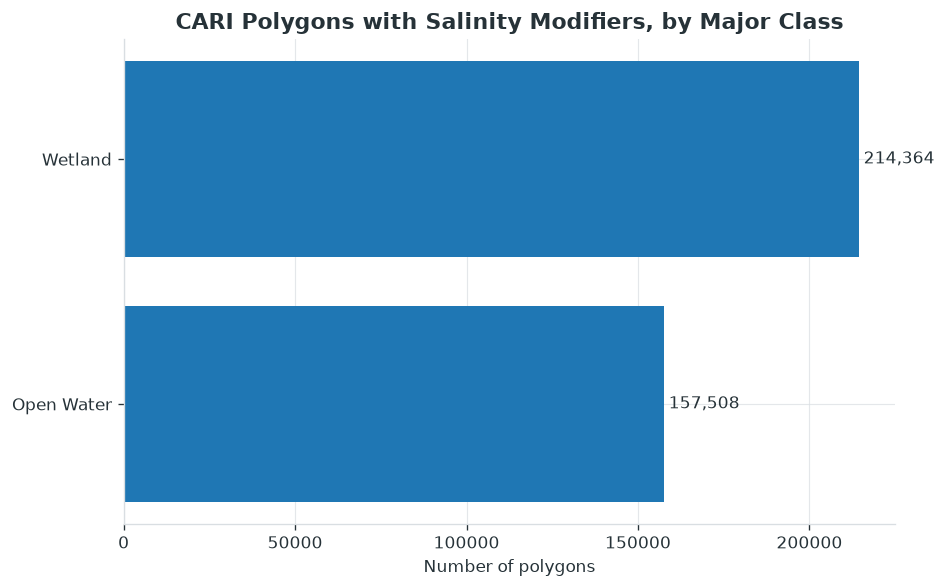

In [14]:

fig, ax = plt.subplots(figsize=(8,5))

ax.barh(
    plot_data.index.astype(str),
    plot_data.values
)

ax.set_title( "CARI Polygons with Salinity Modifiers, by Major Class")
ax.set_xlabel("Number of polygons")
ax.set_ylabel("")

# Count labels
for i, value in enumerate(plot_data.values):
    ax.text(value, i, f" {value:,}", va="center")

plt.tight_layout()
plt.savefig(
    FIG_DIR / "O1_cari_majorclass.png",
    bbox_inches = "tight"
)
plt.show()



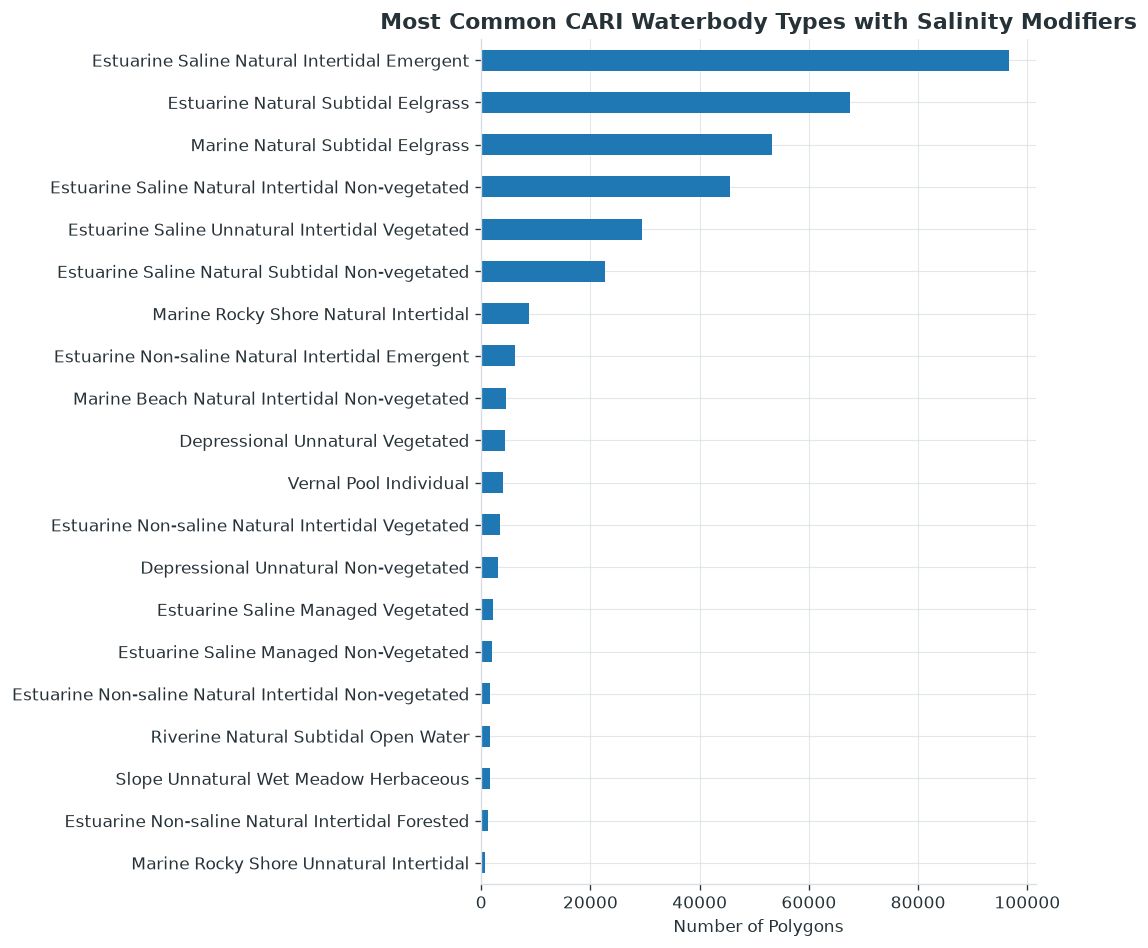

In [15]:
### Fig 1B: Detailed CARI Waterbody Types, map
type_col = "clicklabel"

type_counts = (
    cari_sal[type_col]
    .value_counts()
    .sort_values(ascending=False)
)

# Just keeping most common categories for readability 
top_n = 20 
top_types = type_counts.head(top_n).sort_values()

fig,ax = plt.subplots(figsize=(9,8))

top_types.plot(
    kind="barh",
    ax=ax
)

ax.set_title(f"Most Common CARI Waterbody Types with Salinity Modifiers")
ax.set_xlabel("Number of Polygons")
ax.set_ylabel("")

plt.tight_layout()
plt.savefig(
    FIG_DIR / "O2_cari_waterbody_type.png",
    bbox_inches = "tight"
)

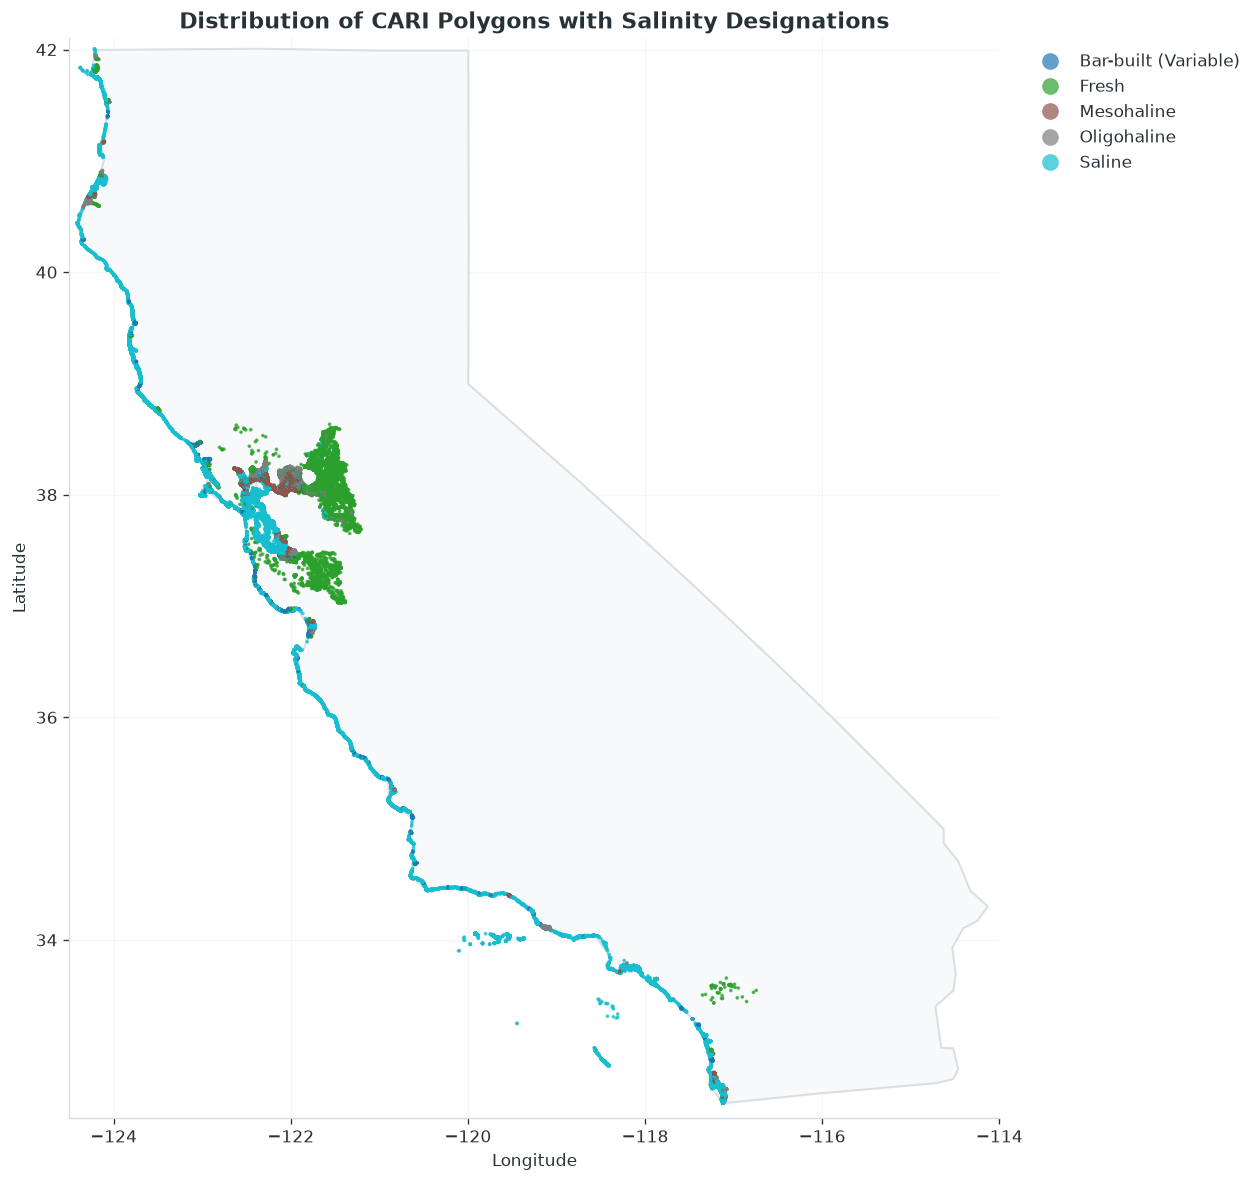

In [16]:
# Plotting map of CARI distribution with salinity modifiers, based on salinity type 

# Convert CARI polygons to representative points and reproject to WGS84
cari_sal_points = cari_sal.copy()
cari_sal_points["geometry"] = cari_sal_points.geometry.representative_point()
cari_sal_points = cari_sal_points.to_crs("EPSG:4326")

# Initialize figure (overriding default figsize for a taller map layout)
fig, ax = plt.subplots(figsize=(10, 12))

url = "https://raw.githubusercontent.com/PublicaMundi/MappingAPI/master/data/geojson/us-states.json"
us_states = gpd.read_file(url)
ca_state = us_states[us_states["name"] == "California"].to_crs("EPSG:4326")
ca_state.plot(
    ax=ax,
    color="#F7F9FA",  # Very light off-white fill
    edgecolor=COLORS["light_gray"],  # Clean subtle border using your palette
    linewidth=1.2,
)
# Plot your salinity designation points
cari_sal_points.plot(
    ax=ax,
    column="salinity_modifier",
    categorical=True,
    legend=True,
    markersize=1.5,
    alpha=0.7,
    legend_kwds={
        "bbox_to_anchor": (1.02, 1),
        "loc": "upper left",
        "frameon": False,
    },
)

ax.set_title("Distribution of CARI Polygons with Salinity Designations")
ax.set_xlabel("Longitude")
ax.set_ylabel("Latitude")
ax.set_xlim(-124.5, -114.0)
ax.set_ylim(32.4, 42.1)
ax.grid(True, alpha=0.3)

plt.savefig(
    FIG_DIR / "03_cari_salinity_distribution.png",
     bbox_inches="tight", dpi=300
)
plt.show()

In [ ]:
# Checking lakes and other non saline sources, 

In [17]:
### 4. CEDEN Analyte 
print("Number of CEDEN records:", len(df_ceden))

display(
    df_ceden["ANALYTE"]
    .value_counts()
    .to_frame("Record count")
)# Only pulled salinity-related fields

Number of CEDEN records: 1629151


,Record count
ANALYTE,
"SpecificConductivity, Total",844418
"Salinity, Total",692156
"SpecificConductivity, Not Recorded",58482
"Chloride, Total",19091
"Chloride, Dissolved",12181
"Chloride, Not Recorded",2146
"Salinity, Dissolved",669
SpecificConductivity,3
Salinity,3


In [ ]:
# Picking select analytes - next time make a copy. Since I ran this once, CEDEN is already cleaned. 

""" analytes = df_ceden['ANALYTE'].unique()
#searching for keywords related to salinity, conductivity, and conductance
salinity_related = [a for a in analytes if any(kw in a.lower() for kw in ['conductance', 'conductivity', 'salinity', 'chloride'])]
print(salinity_related)
salinity_analytes = ['Salinity, Total', 'Salinity', 'Salinity, Dissolved',
                      'SpecificConductivity, Total', 'SpecificConductivity',
                      'SpecificConductivity, Not Recorded', 'SpecificConductivity, Dissolved',
                      'Chloride, Total', 'Chloride, Dissolved', 'Chloride, Not Recorded']
# Creates a temporary true false mask for the analytes of interest, then groups by analyte and unit to get counts. Move to last line in cell to display
df_ceden[df_ceden['ANALYTE'].isin(salinity_analytes)].groupby(['ANALYTE', 'UNIT']).size()
df_ceden_salinity = df_ceden[df_ceden['ANALYTE'].isin(salinity_analytes)].copy()
df_ceden_salinity.shape """

In [18]:
#Drop entries missing lat and long. EDUT want count of how many missing lat long
df_ceden_salinity = df_ceden.dropna(subset=['LATITUDE', 'LONGITUDE'])
# Extract unique STATIONCODE and STATIONNAME combinations to avoid duplicates in the GeoDataFrame - fix next time, too critical
df_ceden_sal_u = df_ceden_salinity.drop_duplicates(subset=['STATIONCODE', 'STATIONNAME'])
# Drop entries with missing or NaN values in the 'RESULT' column
df_ceden_sal_u = df_ceden_sal_u.dropna(subset=['RESULT'])
df_ceden_sal_u.shape

(12116, 94)

In [19]:
## 5. NWIS Cleaning 
print("Number of NIWS records", len(df_nwis))

display(
    df_nwis['CharacteristicName']
    .value_counts()
    .to_frame("Record count")
)# Only pulled salinity-related fields

Number of NIWS records 1428878


,Record count
CharacteristicName,
Specific conductance,944295
Salinity,356827
Chloride,127756


In [ ]:
# If preparing for actual dataset, check units and do necessary conversions

In [32]:
""" # Again - already cleaned without making a copy. Recorded here for repeatability
# Checking what values exist for NWIS CharacteristicName, name of analyte. 
df_nwis['CharacteristicName'].value_counts()
# Looking at result values, whcih collumn do we want. ResultMeasureValue, ResultStatusIdentifier
df_nwis['ResultStatusIdentifier'].value_counts();
# Print values of ResultMeasureValue to see what they look like
df_nwis['ResultMeasure/MeasureUnitCode'].value_counts();
# Filtering NWIS as well. Dropping any without lat long, 
df_nwis = df_nwis.dropna(subset=['ActivityLocation/LatitudeMeasure', 'ActivityLocation/LongitudeMeasure'])
df_nwis.shape
# Dropping without any result values, ResultMeasureValue or unit. ResultMeasureValue is the actual measurement, ResultMeasure/MeasureUnitCode is the unit of measurement.
df_nwis = df_nwis.dropna(subset=['ResultMeasureValue', 'ResultMeasure/MeasureUnitCode'])
df_nwis.shape
# Keeping only columns needed. MonitoringLocationIdentifier, MonitoringLocationName, ActivityLocation/LatitudeMeasure, ActivityLocation/LongitudeMeasure, ActivityStartDate, CharacteristicName, ResultMeasureValue, ResultMeasure/MeasureUnitCode, ResultSampleFractionText, ResultDetectionConditionText, ResultStatusIdentifier, MeasureQualifierCode, OrganizationIdentifier, OrganizationFormalName, USGSPCode
df_nwis_sal = df_nwis[['MonitoringLocationIdentifier', 'MonitoringLocationName', 'ActivityLocation/LatitudeMeasure', 'ActivityLocation/LongitudeMeasure', 'ActivityStartDate', 'CharacteristicName', 'ResultMeasureValue', 'ResultMeasure/MeasureUnitCode', 'ResultSampleFractionText', 'ResultDetectionConditionText', 'ResultStatusIdentifier', 'MeasureQualifierCode', 'OrganizationIdentifier', 'OrganizationFormalName', 'USGSPCode']]
#Keep only columns needed: STATIONCODE, STATIONNAME, LATITUDE, LONGITUDE, ANALYTE, UNIT, RESULT, RESULTQUALCODE, MDL, RL
df_ceden_sal_u = df_ceden_sal_u[['STATIONCODE', 'STATIONNAME', 'LATITUDE', 'LONGITUDE', 'ANALYTE', 'UNIT', 'RESULT', 'RESULTQUALCODE', 'MDL', 'RL']]
df_ceden_sal_u.head() """
df_ceden_sal_u.shape

(12116, 94)

In [20]:
# Safe to Swim data 
print("Safe-to-Swim records:", len(df_s2s))
print("\nCollumns:")
print(df_s2s.columns.tolist)

print("\nMissing Coordinates:")
print(
    df_s2s[
         ["TARGETLONGITUDE", "TARGETLATITUDE"]
    ].isna().any(axis=1).sum()
)

print("\nUnique station codes:")
print(df_s2s["STATIONCODE"].nunique())

Safe-to-Swim records: 6648

Collumns:
<bound method IndexOpsMixin.tolist of Index(['STATIONCODE', 'STATIONNAME', 'STATIONDESCRIPTION', 'TARGETLATITUDE',
       'TARGETLONGITUDE', 'COUNTY', 'RB_NUMBER', 'REGIONAL_BOARD',
       'DATASOURCE'],
      dtype='str')>

Missing Coordinates:
0

Unique station codes:
6648


In [21]:
# Building point dataset and GeoDataFrame from S2S
s2s_locations = df_s2s.dropna(
    subset=["TARGETLONGITUDE", "TARGETLATITUDE"]
).copy()

gdf_s2s = gpd.GeoDataFrame(
    s2s_locations,
    geometry=gpd.points_from_xy(
        s2s_locations["TARGETLONGITUDE"],
        s2s_locations["TARGETLATITUDE"]
    ),
    crs="EPSG:4326",
)

print("Safe-to-Swim point records:", len(gdf_s2s))
print("Safe-to-Swim unique station records:", gdf_s2s["STATIONCODE"].nunique())


Safe-to-Swim point records: 6648
Safe-to-Swim unique station records: 6648


In [22]:
# Converting NWIS and CEDEN into GeoDataFrames 

# CEDEN Unique station locations
gdf_ceden = gpd.GeoDataFrame(
   df_ceden_sal_u.copy(),
   geometry = gpd.points_from_xy(
       df_ceden_sal_u["LONGITUDE"],
       df_ceden_sal_u["LATITUDE"]
   ),
   crs="EPSG:4326",
)

#NWIS Unique monitioring locations
df_nwis_sal_u=(
    df_nwis[
        ['MonitoringLocationIdentifier', 'MonitoringLocationName', 'ActivityLocation/LatitudeMeasure', 'ActivityLocation/LongitudeMeasure'
        ]
    ]
    .drop_duplicates()
    .copy()
)

gdf_nwis = gpd.GeoDataFrame(
    df_nwis_sal_u,
    geometry=gpd.points_from_xy(
        df_nwis_sal_u['ActivityLocation/LongitudeMeasure'],
        df_nwis_sal_u['ActivityLocation/LatitudeMeasure']
    ),
    crs="EPSG:4326"
)

print("CEDEN CRS:", gdf_ceden.crs)
print("NWIS CRS:", gdf_nwis.crs)
print("Safe-to-Swim CRS:", gdf_s2s.crs)
print("CARI CRS:", gdf_cari.crs)

# Reproject point datasets, can't make gdf's in same crs because long and lat measured in degrees, but cari crs in meters

gdf_ceden = gdf_ceden.to_crs(gdf_cari.crs)
gdf_s2s = gdf_s2s.to_crs(gdf_cari.crs)
gdf_nwis= gdf_nwis.to_crs(gdf_cari.crs)

assert gdf_ceden.crs == gdf_cari.crs
assert gdf_s2s.crs == gdf_cari.crs
assert gdf_nwis.crs == gdf_cari.crs

CEDEN CRS: EPSG:4326
NWIS CRS: EPSG:4326
Safe-to-Swim CRS: EPSG:4326
CARI CRS: EPSG:6414


In [ ]:
# Compute spatial joins, preserving all point-polygon matches rather than assume one-to-one
cari_join = cari_sal[
    [
        "CARI_id",
        "major_class",
        "clicklabel",
        "leglabellevel1",
        "salinity_modifier",
        "geometry",
    ]
].copy()

print("CARI polygons in analysis:", len(cari_join))
print("Unique CARI IDs:", cari_join["CARI_id"].nunique())


CARI polygons in analysis: 371872
Unique CARI IDs: 371872


In [24]:
# Join function
def join_monitoring_to_cari(points, cari_polygons): #spatiall join monitoring locations to CARI polygns, with intersects. Multiple matches are kept
    return gpd.sjoin(
        points,
        cari_polygons,
        how="left",
        predicate="intersects"
    )


In [26]:
# Preform joins
ceden_joined = join_monitoring_to_cari(
    gdf_ceden,
    cari_join
)

nwis_joined = join_monitoring_to_cari(
    gdf_nwis,
    cari_join
)

s2s_joined = join_monitoring_to_cari(
    gdf_s2s,
    cari_join
)

print("CEDEN joined records:", len(ceden_joined))
print("NWIS joined records:", len(nwis_joined))
print("Safe-to-Swim joined records:", len(s2s_joined))

CEDEN joined records: 12116
NWIS joined records: 30019
Safe-to-Swim joined records: 6648


In [27]:
# Check how many s2s monitoring locations have matches 
def print_match_counts(joined, station_col, source_name):
    total = joined[station_col].nunique()

    matched = joined.loc[
        joined["CARI_id"].notna(),
        station_col
    ].nunique()

    print(
        f"{source_name}: "
        f"{matched:,} / {total:,} unique locations matched"
    )
    return matched, total

nwis_station_match = print_match_counts(
    nwis_joined,
    "MonitoringLocationIdentifier",
    "NIWS"
)

ceden_station_match = print_match_counts(
    ceden_joined,
    "STATIONCODE",
    "CEDEN"
)

s2s_station_match = print_match_counts(
    s2s_joined,
    "STATIONCODE",
    "Safe-to-Swim"
)

NIWS: 1,772 / 29,614 unique locations matched
CEDEN: 1,107 / 12,111 unique locations matched
Safe-to-Swim: 1,253 / 6,648 unique locations matched


In [28]:
# Compute coverage within CARI salinity subset

def coverage_summary(
    joined,
    station_col,
    source_name,
    cari_polygons
):
    matched = joined.dropna(subset=["CARI_id"])

    total_locations = joined[station_col].nunique()
    matched_locations = matched[station_col].nunique()

    total_polygons = cari_polygons["CARI_id"].nunique()
    matched_polygons = matched["CARI_id"].nunique()

    percentage = (
        matched_polygons / total_polygons * 100
        if total_polygons > 0
        else np.nan
    )

    return {
        "Source": source_name,
        "Total unique locations": total_locations,
        "Locations intersecting CARI": matched_locations,
        "Total CARI polygons": total_polygons,
        "CARI polygons intersected": matched_polygons,
        "Percent of CARI polygons intersected": percentage,
    }

In [30]:
# Coverage comparison

coverage = pd.DataFrame([
    coverage_summary(
        ceden_joined,
        "STATIONCODE",
        "CEDEN",
        cari_join
    ),

    coverage_summary(
        nwis_joined,
        "MonitoringLocationIdentifier",
        "NWIS",
        cari_join
    ),

    coverage_summary(
        s2s_joined,
        "STATIONCODE",
        "Safe-to-Swim",
        cari_join
    )
])

display(
    coverage.style.format({
        "Percent of CARI polygons intersected": "{:.2f}%"
    })
)

,Source,Total unique locations,Locations intersecting CARI,Total CARI polygons,CARI polygons intersected,Percent of CARI polygons intersected
0,CEDEN,12111,1107,371872,362,0.10%
1,NWIS,29614,1772,371872,386,0.10%
2,Safe-to-Swim,6648,1253,371872,532,0.14%


In [33]:
# CEDEN and NWIS Coverage

ceden_matched_ids = set(
    ceden_joined["CARI_id"].dropna().unique()
)

nwis_matched_ids = set(
    nwis_joined["CARI_id"].dropna().unique()
)

combined_matched_ids = (
    ceden_matched_ids | nwis_matched_ids
)

ceden_and_nwis_summary = pd.DataFrame([
    {
        "Source": "CEDEN",
        "Matched CARI polygons": len(ceden_matched_ids)
    },
    {
        "Source": "NWIS",
        "Matched CARI polygons": len(nwis_matched_ids)
    },
    {
        "Source": "CEDEN or NWIS",
        "Matched CARI polygons": len(combined_matched_ids)
    }
])

ceden_and_nwis_summary["Total CARI polygons"] = (
    cari_join["CARI_id"].nunique()
)

ceden_and_nwis_summary["Percent intersected"] = (
    ceden_and_nwis_summary["Matched CARI polygons"]
    / ceden_and_nwis_summary["Total CARI polygons"]
    * 100
)

display(
    ceden_and_nwis_summary.style.format({
        "Percent intersected": "{:.2f}%"
    })
)

,Source,Matched CARI polygons,Total CARI polygons,Percent intersected
0,CEDEN,362,371872,0.10%
1,NWIS,386,371872,0.10%
2,CEDEN or NWIS,632,371872,0.17%


In [34]:
# Coverage by major class

def polygon_coverage(joined, source_name, cari_polygons):
    """
    Return one row per CARI polygon and a boolean indicating
    whether it intersects at least one monitoring location.
    """

    matched_ids = set(
        joined["CARI_id"].dropna().unique()
    )

    result = (
        cari_polygons[
            ["CARI_id", "major_class"]
        ]
        .drop_duplicates(subset=["CARI_id"])
        .copy()
    )

    result[f"{source_name}_matched"] = (
        result["CARI_id"].isin(matched_ids)
    )

    return result

ceden_coverage = polygon_coverage(
    ceden_joined, "CEDEN", cari_join
)

nwis_coverage = polygon_coverage(
    nwis_joined, "NWIS", cari_join
)

s2s_coverage = polygon_coverage(
    s2s_joined, "S2S", cari_join
)

coverage_by_polygon = (
    ceden_coverage
    .merge(
        nwis_coverage[["CARI_id", "NWIS_matched"]],
        on="CARI_id"
    )
    .merge(
        s2s_coverage[["CARI_id", "S2S_matched"]],
        on="CARI_id"
    )
)

coverage_by_polygon["Either_CEDEN_NWIS"] = (
    coverage_by_polygon["CEDEN_matched"]
    | coverage_by_polygon["NWIS_matched"]
)

In [35]:
coverage_by_class = (
    coverage_by_polygon
    .groupby("major_class", dropna=False)
    .agg(
        total_polygons=("CARI_id", "nunique"),
        CEDEN=("CEDEN_matched", "sum"),
        NWIS=("NWIS_matched", "sum"),
        CEDEN_or_NWIS=("Either_CEDEN_NWIS", "sum"),
        Safe_to_Swim=("S2S_matched", "sum")
    )
)

for col in [
    "CEDEN",
    "NWIS",
    "CEDEN_or_NWIS",
    "Safe_to_Swim"
]:
    coverage_by_class[f"{col}_pct"] = (
        coverage_by_class[col]
        / coverage_by_class["total_polygons"]
        * 100
    )

display(coverage_by_class.round(1))

,total_polygons,CEDEN,NWIS,CEDEN_or_NWIS,Safe_to_Swim,CEDEN_pct,NWIS_pct,CEDEN_or_NWIS_pct,Safe_to_Swim_pct
major_class,,,,,,,,,
Open Water,157508,253,248,403,361,0.2,0.2,0.3,0.2
Wetland,214364,109,138,229,171,0.1,0.1,0.1,0.1


In [38]:
# Map of data
MAP_CRS = "EPSG:6414"

cari_map = cari_join.to_crs(MAP_CRS)
ceden_map = gdf_ceden.to_crs(MAP_CRS)
nwis_map = gdf_nwis.to_crs(MAP_CRS)
s2s_map = gdf_s2s.to_crs(MAP_CRS)

# Remove duplicate station codes for map display.
# If a station has multiple coordinate locations, this keeps
# the first unique station-coordinate combination.
ceden_map = ceden_map.drop_duplicates(
    subset=["STATIONCODE"]
)

nwis_map = nwis_map.drop_duplicates(
    subset=["MonitoringLocationIdentifier"]
)

s2s_map = s2s_map.drop_duplicates(
    subset=["STATIONCODE"]
)


Simplifying geometries for rendering...


GEOSException: bad allocation

In [ ]:
# Map of CEDEN and NWIS data 
# Plotting map of CARI distribution with salinity modifiers, based on salinity type 

s2s_locations df_ceden_sal_u
# Convert CARI polygons to representative points and reproject to WGS84
cari_sal_points = cari_sal.copy()
cari_sal_points["geometry"] = cari_sal_points.geometry.representative_point()
cari_sal_points = cari_sal_points.to_crs("EPSG:4326")

# Initialize figure (overriding default figsize for a taller map layout)
fig, ax = plt.subplots(figsize=(10, 12))

url = "https://raw.githubusercontent.com/PublicaMundi/MappingAPI/master/data/geojson/us-states.json"
us_states = gpd.read_file(url)
ca_state = us_states[us_states["name"] == "California"].to_crs("EPSG:4326")
ca_state.plot(
    ax=ax,
    color="#F7F9FA",  # Very light off-white fill
    edgecolor=COLORS["light_gray"],  # Clean subtle border using your palette
    linewidth=1.2,
)
# Plot your salinity designation points
cari_sal_points.plot(
    ax=ax,
    column="salinity_modifier",
    categorical=True,
    legend=True,
    markersize=1.5,
    alpha=0.7,
    legend_kwds={
        "bbox_to_anchor": (1.02, 1),
        "loc": "upper left",
        "frameon": False,
    },
)

ax.set_title("Distribution of CARI Polygons with Salinity Designations")
ax.set_xlabel("Longitude")
ax.set_ylabel("Latitude")
ax.set_xlim(-124.5, -114.0)
ax.set_ylim(32.4, 42.1)
ax.grid(True, alpha=0.3)

plt.savefig(
    FIG_DIR / "04_nwiw_ceden_data.png"
     bbox_inches="tight", dpi=300
)
plt.show()

GEOSException: bad allocation

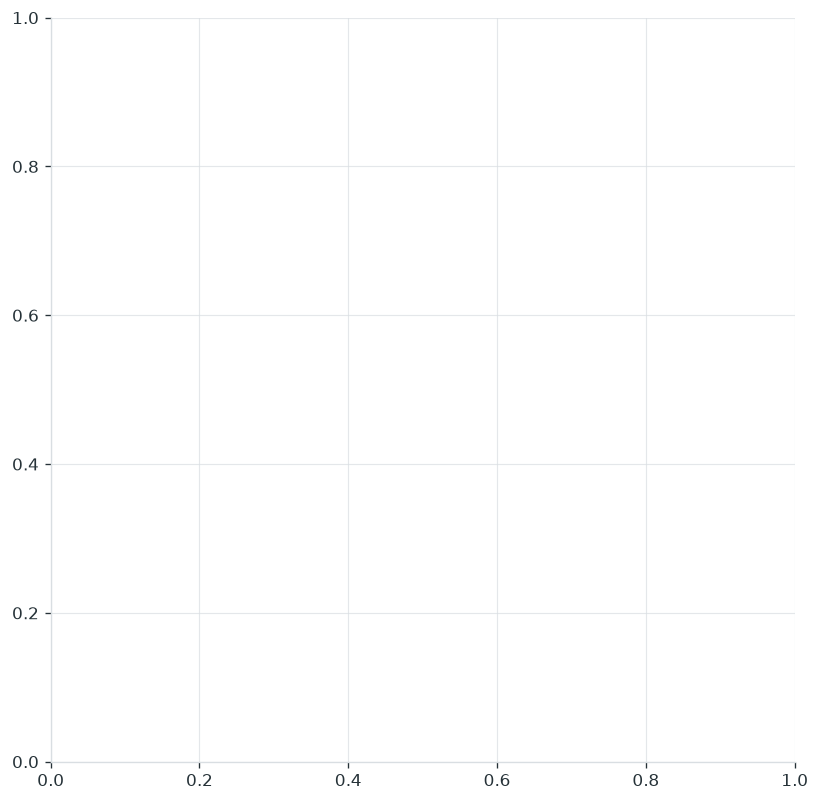

In [44]:
fig, ax = plt.subplots(figsize=(8, 10))

cari_map.plot(
    ax=ax,
    color="whitesmoke",
    edgecolor="lightgray",
    linewidth=0.15
)

ceden_map.plot(
    ax=ax,
    color="tab:blue",
    markersize=7,
    alpha=0.65,
    label="CEDEN"
)

nwis_map.plot(
    ax=ax,
    color="tab:orange",
    markersize=7,
    alpha=0.65,
    label="NWIS"
)

ax.set_title(
    "Salinity-Related Monitoring Locations and CARI Waterbodies",
    pad=15
)

ax.legend(
    loc="lower left",
    frameon=True
)

ax.set_axis_off()

plt.tight_layout()

plt.savefig(
    FIGURE_DIR / "04_monitoring_locations.png",
    bbox_inches="tight"
)

plt.show()

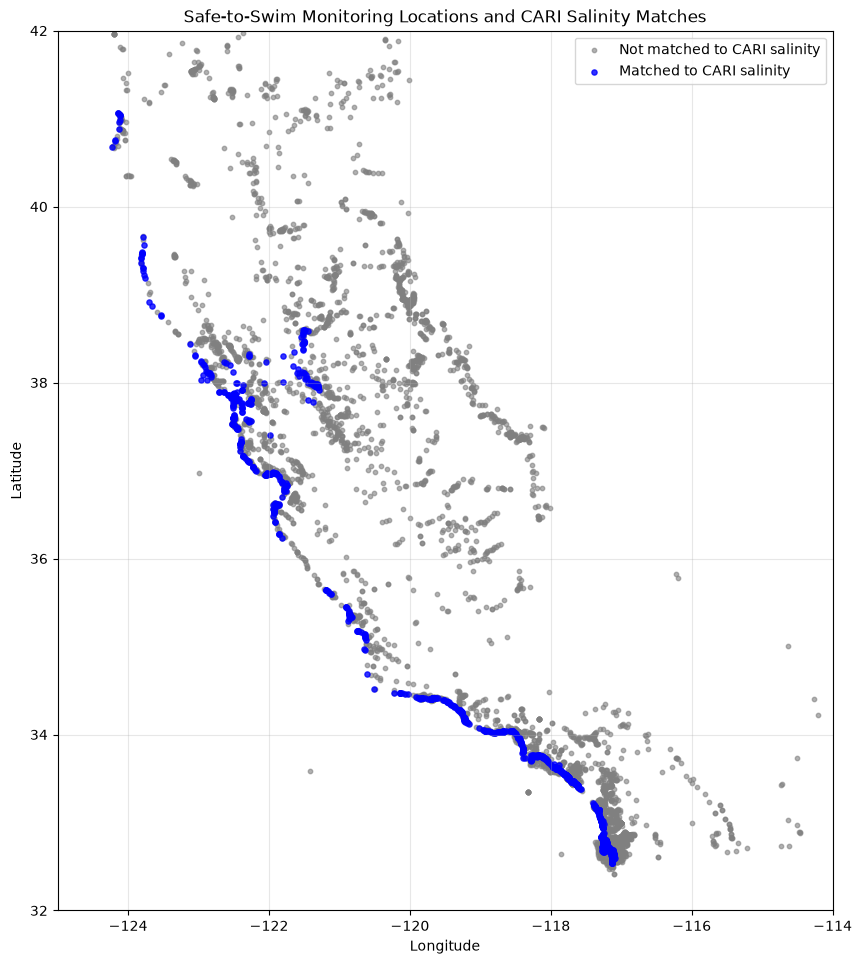

In [30]:
# Quick map of Safe-to-Swim monitoring locations matched to CARI salinity polygons

# Identify stations matched to a CARI salinity polygon
matched_station_codes = set(
    s2s_cari_sal.loc[
        s2s_cari_sal["CARI_id"].notna(),
        "STATIONCODE"
    ]
)

# Reproject points to longitude/latitude for plotting
s2s_map = gdf_s2s.to_crs("EPSG:4326").copy()
s2s_map["matched_cari_salinity"] = s2s_map["STATIONCODE"].isin(
    matched_station_codes
)

fig, ax = plt.subplots(figsize=(10, 12))

# Plot unmatched locations first
s2s_map[~s2s_map["matched_cari_salinity"]].plot(
    ax=ax,
    color="gray",
    markersize=10,
    alpha=0.6,
    label="Not matched to CARI salinity"
)

# Plot matched locations
s2s_map[s2s_map["matched_cari_salinity"]].plot(
    ax=ax,
    color="blue",
    markersize=14,
    alpha=0.8,
    label="Matched to CARI salinity"
)

ax.set_xlim(-125, -114)
ax.set_ylim(32, 42)
ax.set_title("Safe-to-Swim Monitoring Locations and CARI Salinity Matches")
ax.set_xlabel("Longitude")
ax.set_ylabel("Latitude")
ax.legend()
ax.grid(True, alpha=0.3)

plt.show()

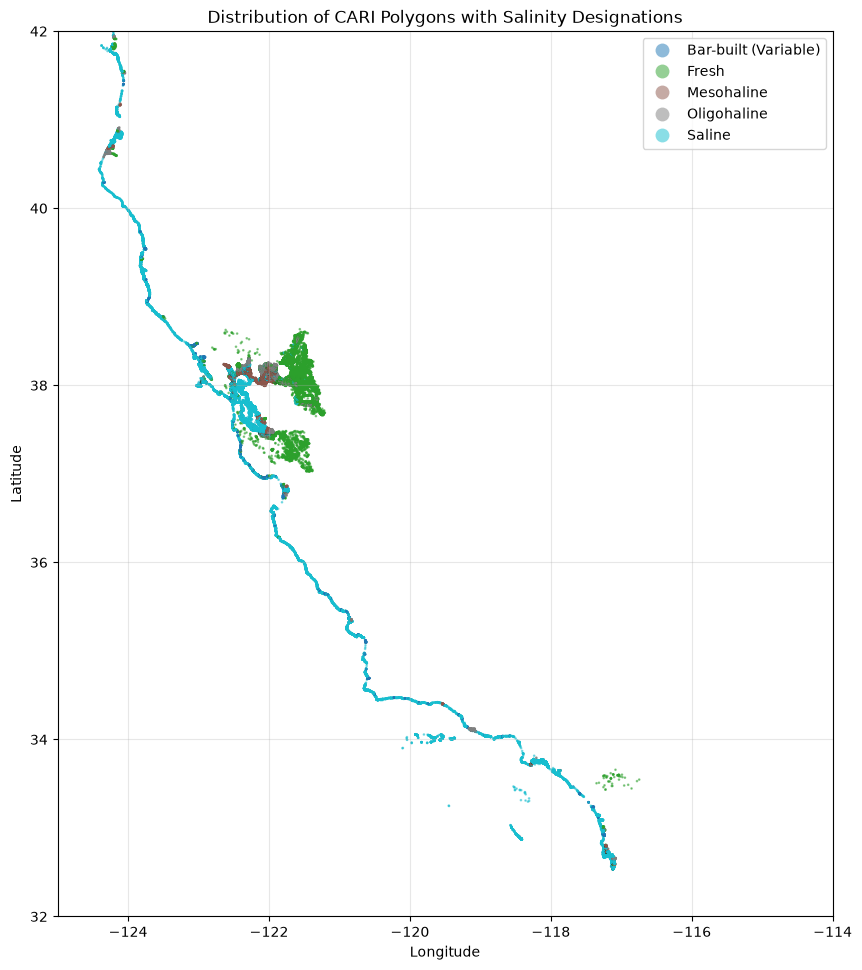

In [31]:
# Quick point map of CARI polygons with salinity designations

cari_sal_points = cari_sal.copy()
cari_sal_points["geometry"] = cari_sal_points.geometry.representative_point()
cari_sal_points = cari_sal_points.to_crs("EPSG:4326")

fig, ax = plt.subplots(figsize=(10, 12))

cari_sal_points.plot(
    ax=ax,
    column="salinity_modifier",
    categorical=True,
    legend=True,
    markersize=0.8,
    alpha=0.5
)

ax.set_title("Distribution of CARI Polygons with Salinity Designations")
ax.set_xlabel("Longitude")
ax.set_ylabel("Latitude")
ax.set_xlim(-125, -114)
ax.set_ylim(32, 42)
ax.grid(True, alpha=0.3)

plt.show()